# HRRR-AK forcing at 2021 snow-pit and model sites

Compare C161, TKG3, TKG2, DG1, and the existing TKG4 model point. The TKG4 pit is included separately to audit its small coordinate offset and different recorded elevation. Run top to bottom with the **JIF snow modeling** kernel; no other notebook or generated tables are required.

The map follows the zoom panel in `02_radar_hrrrak_dem_coverage.ipynb`. Forcing comes from its existing WY2021 HRRR file, without interpolation, lapse rates, pressure adjustments, or elevation corrections. These are stored reprojected HRRR cells, not verified unique native HRRR cells.

## 1. Configuration

Pit and radar coordinates provisionally use **WGS 84 / UTM Zone 8N (EPSG:32608)** because their horizontal datums are unconfirmed. Use the same transformer for both. The TKG4 model longitude/latitude and 1,120 m elevation come from `sites/tkg4/2_create_snowpack_smet_forcing_hrrrak_tkg4_WY2020-WY2025.ipynb`; they are configured explicitly below. Pit elevations come from the CSV and are not assigned to the model point. Vertical datum consistency is unverified.

The map timestamp is illustrative, not a confirmed radar survey date. Time values are interpreted as UTC, following the reference notebook. Output paths follow `radar/figures/` and `radar/data/`.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray
import rasterio
from rasterio.warp import transform_bounds
from pyproj import CRS, Transformer
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from IPython.display import display

HRRR_PATH = Path('/hdd/snow_hydrology/hrrrak/icefield_domain/netcdf/hrrrak_merged_grib_f567_WY2021_utm.nc')
PIT_PATH = Path('/hdd/snow_hydrology/JIF_radar/jif_snow_pit_sites_2021.csv')
RADAR_PATH = Path('/hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv')
DEM_PATH = Path('/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic/jif_tiles_utm8n_20m.tif')
PIT_IDS = ['C161', 'TKG3', 'TKG2', 'DG1']
CONTEXT_PIT_ID = 'TKG4'
MODEL_LON, MODEL_LAT, MODEL_ELEVATION_M = -134.23708, 58.63447, 1120
SOURCE_EPSG = 32608
MAP_TIME_UTC = pd.Timestamp('2021-05-01T12:00:00')
TIME_TOLERANCE = pd.Timedelta('1h')
# General radar collection dates, inclusive; UTC follows this notebook's time axis.
RADAR_COLLECTION_START = pd.Timestamp('2021-07-09')
RADAR_COLLECTION_END_EXCLUSIVE = pd.Timestamp('2021-07-16')
SAVE_OUTPUTS = True
SITE_COLORS = {'C161': '#0072b2', 'TKG3': '#d55e00', 'TKG2': '#009e73',
               'DG1': '#8c564b', 'TKG4 model': '#7b3294', 'TKG4 pit': '#e69f00'}
SITE_ORDER = [*PIT_IDS, 'TKG4 model', 'TKG4 pit']
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'radar' / '02_radar_hrrrak_dem_coverage.ipynb').is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError('Launch from jif_snow_modeling/ or radar/.')
FIGURE_DIR, DATA_DIR = REPO_ROOT / 'radar/figures', REPO_ROOT / 'radar/data'
REFERENCE_PATH = REPO_ROOT / 'radar/02_radar_hrrrak_dem_coverage.ipynb'
reference_sha256 = hashlib.sha256(REFERENCE_PATH.read_bytes()).hexdigest()
for path in [HRRR_PATH, PIT_PATH, RADAR_PATH, DEM_PATH]:
    if not path.is_file():
        raise FileNotFoundError(path)
if SAVE_OUTPUTS:
    FIGURE_DIR.mkdir(exist_ok=True)
    DATA_DIR.mkdir(exist_ok=True)
print('Python:', sys.executable)
print('Verified case-sensitive CSV path:', PIT_PATH.resolve())

Python: /home/cassie/programs/miniforge3/envs/jif_snow_modeling/bin/python
Verified case-sensitive CSV path: /hdd/snow_hydrology/JIF_radar/jif_snow_pit_sites_2021.csv


## 2. Load locations and verify forcing metadata

Inspect quality flags before selection: MG2's suspicious northing is preserved in the source table and excluded; MG5's lower-bound depth is not among the selected sites. Date and sampling flags remain in the selected-site table. Sort spatial axes west-to-east and south-to-north, as in the reference notebook. Require unique increasing timestamps, equality of `time` and `valid_time`, and hourly-aligned times; missing hours will be made explicit during aggregation.

Check per-variable GRIB metadata: `temp` must be 2 m air temperature (K), `pressure` must be **surface** pressure (Pa), and `orog` must be in metres. Dataset-level metadata are not used to identify variables.

In [2]:
pits = pd.read_csv(PIT_PATH, encoding='utf-8-sig', parse_dates=['pit_date'])
pits['quality_flags'] = pits.quality_flags.fillna('')
if not pits.site_id.is_unique:
    raise ValueError('Pit IDs must be unique.')
flagged = pits.loc[pits.quality_flags.ne(''), ['site_id', 'quality_flags']]
display(flagged)
selected_ids = [*PIT_IDS, CONTEXT_PIT_ID]
selected_pits = pits.set_index('site_id').loc[selected_ids].reset_index().copy()
if selected_pits.quality_flags.str.contains('northing_outside_study_area', regex=False).any():
    raise ValueError('Selected pit has a flagged northing; review before mapping.')
if not np.isfinite(selected_pits[['east', 'north']]).all().all():
    raise ValueError('Selected pit coordinates must be finite.')
selected_pits['label'] = selected_pits.site_id.replace({'TKG4': 'TKG4 pit'})
selected_pits['kind'] = 'pit'
selected_pits['pit_elevation_m'] = selected_pits.elevation_m
selected_pits['model_elevation_m'] = np.nan

with xr.open_dataset(HRRR_PATH, decode_coords='all') as ds:
    grid_crs = CRS.from_user_input(ds.rio.crs)
    if grid_crs.to_epsg() != 32608:
        raise ValueError(f'Unexpected HRRR CRS: {grid_crs}')
    times = pd.DatetimeIndex(ds.time.values)
    if not times.is_unique or not times.is_monotonic_increasing or times.hasnans:
        raise ValueError('Expected finite, unique, increasing times.')
    if not np.array_equal(ds.valid_time.values, ds.time.values):
        raise ValueError('time differs from valid_time: resolve timestamp semantics.')
    if not (times == times.floor('h')).all():
        raise ValueError('Timestamps are not hourly-aligned.')
    display(pd.DataFrame([{'variable': name, **{key: ds[name].attrs.get(key)
        for key in ['long_name', 'units', 'GRIB_shortName', 'GRIB_cfName', 'typeOfLevel', 'level']}}
        for name in ['temp', 'pressure', 'orog']]))
    ta, pa, za = [ds[v].attrs for v in ['temp', 'pressure', 'orog']]
    assert ta['units'] == 'K' and ta['typeOfLevel'] == 'heightAboveGround' and ta['level'] == 2
    assert ta['GRIB_shortName'] == '2t'
    assert pa['units'] == 'Pa' and pa['typeOfLevel'] == 'surface'
    assert pa['GRIB_shortName'] == 'sp' and pa['GRIB_cfName'] == 'surface_air_pressure'
    assert za['units'] == 'm'
    # Only the one map snapshot is loaded on the full grid.
    sorted_grid = ds[['temp', 'pressure', 'orog']].sortby('x').sortby('y')
    x, y = sorted_grid.x.values, sorted_grid.y.values
    map_index = times.get_indexer([MAP_TIME_UTC], method='nearest', tolerance=TIME_TOLERANCE)[0]
    if map_index < 0:
        raise ValueError('Map time has no timestamp within tolerance.')
    snapshot = sorted_grid[['temp', 'orog']].isel(time=map_index).load()
    forecast_steps_h = np.unique(ds.step.values).astype('timedelta64[h]')
print('Dataset time range (UTC):', times.min(), 'to', times.max())
print('Time increments:', pd.Series(times[1:] - times[:-1]).value_counts().to_dict())
print('time equals valid_time; stored forecast leads:', forecast_steps_h)
print('Map snapshot:', pd.Timestamp(snapshot.time.values), 'UTC')

,site_id,quality_flags
2,H,density_sampled_2021-07-01_after_dig_date
3,TKG5,archived_pit_date_differs_from_paper_table1_gt...
4,TKG3,archived_pit_date_differs_from_paper_table1_gt...
5,TKG4,archived_pit_date_differs_from_paper_table1_gt...
10,MG2,northing_outside_study_area_verify
11,MG5,firn_or_ice_not_reached_depth_is_lower_bound


,variable,long_name,units,GRIB_shortName,GRIB_cfName,typeOfLevel,level
0,temp,2 metre temperature,K,2t,air_temperature,heightAboveGround,2
1,pressure,Surface pressure,Pa,sp,surface_air_pressure,surface,0
2,orog,Orography,m,orog,geopotential_height,surface,0


Dataset time range (UTC): 2020-10-01 05:00:00 to 2021-10-01 04:00:00
Time increments: {Timedelta('0 days 01:00:00'): 8759}
time equals valid_time; stored forecast leads: [5 6 7]
Map snapshot: 2021-05-01 12:00:00 UTC


## 3. Assign cells and extract original forcing

Use cell edges derived from the sorted grid centres and `searchsorted(..., side='right')`, matching the reference. Boundary ties go east/north; outside locations cause an error. Indices below refer to the **sorted stored UTM grid**, not the original NetCDF y order. Extract one hourly series per unique cell using vectorized indices, then reuse it for any colocated sites. No whole-domain time series are loaded.

Retain each site's actual coordinates separately from its extraction cell centre. Compare the TKG4 pit and model coordinates explicitly. The map extent depends only on radar coordinates plus the reference's 6,500 m padding.

In [3]:
def cell_edges(centres):
    centres = np.asarray(centres, dtype=float)
    diffs = np.diff(centres)
    if len(centres) < 2 or not np.all(diffs > 0) or not np.allclose(diffs, diffs[0], rtol=1e-6):
        raise ValueError('Expected regularly spaced increasing grid centres.')
    return np.r_[centres[0] - diffs[0] / 2, (centres[:-1] + centres[1:]) / 2,
                 centres[-1] + diffs[-1] / 2]

x_edges, y_edges = cell_edges(x), cell_edges(y)
hrrr_bounds = (x_edges[0], y_edges[0], x_edges[-1], y_edges[-1])
transform_utm = Transformer.from_crs(SOURCE_EPSG, grid_crs, always_xy=True)
selected_pits['grid_x'], selected_pits['grid_y'] = transform_utm.transform(
    selected_pits.east.to_numpy(), selected_pits.north.to_numpy())
mx, my = Transformer.from_crs(4326, grid_crs, always_xy=True).transform(MODEL_LON, MODEL_LAT)
model = pd.DataFrame([{'site_id': 'TKG4', 'label': 'TKG4 model', 'kind': 'model',
                      'grid_x': mx, 'grid_y': my, 'pit_elevation_m': np.nan,
                      'model_elevation_m': MODEL_ELEVATION_M,
                      'quality_flags': 'Model coordinate/elevation from TKG4 forcing notebook'}])
sites = pd.concat([selected_pits, model], ignore_index=True).set_index('label').loc[SITE_ORDER].reset_index()
sites['col_west_to_east'] = np.searchsorted(x_edges, sites.grid_x, side='right') - 1
sites['row_south_to_north'] = np.searchsorted(y_edges, sites.grid_y, side='right') - 1
if not ((sites.col_west_to_east.between(0, len(x)-1)) &
        sites.row_south_to_north.between(0, len(y)-1)).all():
    raise ValueError('A selected site falls outside the stored HRRR grid.')
sites['cell_id'] = [f'r{r}:c{c}' for r, c in zip(sites.row_south_to_north, sites.col_west_to_east)]
sites['cell_x'] = x[sites.col_west_to_east.to_numpy()]
sites['cell_y'] = y[sites.row_south_to_north.to_numpy()]
sites['distance_to_center_m'] = np.hypot(sites.grid_x - sites.cell_x, sites.grid_y - sites.cell_y)
unique_cells = sites.drop_duplicates('cell_id').reset_index(drop=True)
cell_lookup = {cell: i for i, cell in enumerate(unique_cells.cell_id)}
sites['cell_index'] = sites.cell_id.map(cell_lookup)
with xr.open_dataset(HRRR_PATH, decode_coords='all') as ds:
    source = ds[['temp', 'pressure', 'orog']].sortby('x').sortby('y')
    forcing = source.isel(
        x=xr.DataArray(unique_cells.col_west_to_east.to_numpy(), dims='cell'),
        y=xr.DataArray(unique_cells.row_south_to_north.to_numpy(), dims='cell')).load()
assert forcing.temp.dims == ('time', 'cell')
assert np.array_equal(forcing.time.values, times.values)
assert np.allclose(forcing.x.values, unique_cells.cell_x)
assert np.allclose(forcing.y.values, unique_cells.cell_y)
shared_cells = sites.groupby('cell_id', sort=False).agg(sites=('label', ', '.join), n=('label', 'size'))
print('Shared forcing cells (identical input curves expected):')
display(shared_cells.loc[shared_cells.n > 1])
tkg4_pit = sites.set_index('label').loc['TKG4 pit']
print(f'TKG4 pit–model separation: {np.hypot(tkg4_pit.grid_x-mx, tkg4_pit.grid_y-my):.2f} m')
print('TKG4 pit/model recorded elevations:', tkg4_pit.pit_elevation_m, '/', MODEL_ELEVATION_M, 'm')

radar = pd.read_csv(RADAR_PATH, usecols=['east', 'north'], encoding='utf-8-sig')
finite_radar = np.isfinite(radar[['east', 'north']]).all(axis=1)
radar_x, radar_y = transform_utm.transform(radar.loc[finite_radar, 'east'].to_numpy(),
                                        radar.loc[finite_radar, 'north'].to_numpy())
zoom_bounds = (radar_x.min()-6500, radar_y.min()-6500, radar_x.max()+6500, radar_y.max()+6500)
with rasterio.open(DEM_PATH) as dem:
    dem_bounds = transform_bounds(dem.crs, grid_crs, *dem.bounds, densify_pts=101)
print('Radar rows excluded for nonfinite coordinates:', int((~finite_radar).sum()))
print('Unchanged radar zoom bounds:', zoom_bounds)

Shared forcing cells (identical input curves expected):


,sites,n
cell_id,,
r18:c16,"TKG4 model, TKG4 pit",2


TKG4 pit–model separation: 8.30 m
TKG4 pit/model recorded elevations: 1067.0 / 1120 m
Radar rows excluded for nonfinite coordinates: 0
Unchanged radar zoom bounds: (np.float64(516283.7807), np.float64(6478362.622), np.float64(571659.4375), np.float64(6528391.199))


## 4. Common coverage and monthly means

Use the longest overlapping first-to-last finite range across **both variables and all selected locations**. Retain interior gaps. Reindex to a complete UTC hourly calendar before averaging; a monthly mean is plotted only if **every expected hour in that calendar month is finite for both variables** at that site. Partial edge months and any internally incomplete months remain NaN, breaking the plotted lines. No interpolation or gap filling is performed.

The coverage audit distinguishes missing hours inside the common period from missing hours in full calendar months at its edges. Monthly CSVs retain all months, counts, and flags. HRRR orography is time-dependent in this file: report its min/max and the illustrative map-snapshot elevation; elevation differences use that snapshot and are descriptive only.

In [4]:
site_indices = sites.cell_index.to_numpy()
hourly_temp = pd.DataFrame(forcing.temp.values[:, site_indices] - 273.15, index=times, columns=SITE_ORDER)
hourly_pressure = pd.DataFrame(forcing.pressure.values[:, site_indices] / 100, index=times, columns=SITE_ORDER)
hourly_temp = hourly_temp.where(np.isfinite(hourly_temp))
hourly_pressure = hourly_pressure.where(np.isfinite(hourly_pressure))
coverage_rows = []
for label in SITE_ORDER:
    tv, pv = hourly_temp[label].dropna(), hourly_pressure[label].dropna()
    if tv.empty or pv.empty:
        raise ValueError(f'No temperature/pressure coverage for {label}')
    coverage_rows.append({'label': label, 'temp_start': tv.index.min(), 'temp_end': tv.index.max(),
                          'pressure_start': pv.index.min(), 'pressure_end': pv.index.max()})
coverage = pd.DataFrame(coverage_rows).set_index('label')
common_start = coverage[['temp_start', 'pressure_start']].max().max()
common_end = coverage[['temp_end', 'pressure_end']].min().min()
if common_end < common_start:
    raise ValueError('No common time range.')
common_hours = pd.date_range(common_start, common_end, freq='h')
first_month = common_start.to_period('M').start_time
next_month = (common_end.to_period('M') + 1).start_time
calendar_hours = pd.date_range(first_month, next_month, freq='h', inclusive='left')
ht = hourly_temp.loc[common_start:common_end].reindex(calendar_hours)
hp = hourly_pressure.loc[common_start:common_end].reindex(calendar_hours)
expected_hours = pd.Series(1, index=calendar_hours).resample('MS').sum()
temp_counts, pressure_counts = ht.resample('MS').count(), hp.resample('MS').count()
complete = temp_counts.eq(expected_hours, axis=0) & pressure_counts.eq(expected_hours, axis=0)
monthly_temp = ht.resample('MS').mean().where(complete)
monthly_pressure = hp.resample('MS').mean().where(complete)
monthly_rows = []
for label in SITE_ORDER:
    for month in expected_hours.index:
        monthly_rows.append({'label': label, 'month_UTC': month, 'expected_hours': expected_hours.loc[month],
            'temp_hours': temp_counts.loc[month, label], 'pressure_hours': pressure_counts.loc[month, label],
            'complete_both': bool(complete.loc[month, label]),
            'temperature_C': monthly_temp.loc[month, label],
            'surface_pressure_hPa': monthly_pressure.loc[month, label]})
monthly_audit = pd.DataFrame(monthly_rows)
print(f'Longest common forcing period: {common_start} to {common_end} UTC ({len(common_hours):,} expected hours).')
print('Incomplete months omitted from both curves:')
display(monthly_audit.loc[~monthly_audit.complete_both,
                        ['label', 'month_UTC', 'expected_hours', 'temp_hours', 'pressure_hours']])
valid_months = complete.index[complete.all(axis=1)]
if valid_months.empty:
    raise ValueError('No complete common calendar months to plot.')
print(f'Complete monthly means: {valid_months.min():%Y-%m} to {valid_months.max():%Y-%m}; '
      f'{len(valid_months)} months complete at every site.')

summary = sites.merge(coverage, left_on='label', right_index=True, validate='one_to_one')
summary['available_start_UTC'] = summary[['temp_start', 'pressure_start']].max(axis=1)
summary['available_end_UTC'] = summary[['temp_end', 'pressure_end']].min(axis=1)
summary['temp_missing_common_hours'] = [hourly_temp.reindex(common_hours)[s].isna().sum() for s in SITE_ORDER]
summary['pressure_missing_common_hours'] = [hourly_pressure.reindex(common_hours)[s].isna().sum() for s in SITE_ORDER]
summary['complete_months'] = [complete[s].sum() for s in SITE_ORDER]
summary['omitted_months'] = [int((~complete[s]).sum()) for s in SITE_ORDER]
summary['hrrr_terrain_snapshot_m'] = [float(snapshot.orog.values[r, c])
    for r, c in zip(summary.row_south_to_north, summary.col_west_to_east)]
summary['hrrr_terrain_min_m'] = forcing.orog.min('time', skipna=True).values[site_indices]
summary['hrrr_terrain_max_m'] = forcing.orog.max('time', skipna=True).values[site_indices]
summary['pit_minus_hrrr_m'] = summary.pit_elevation_m - summary.hrrr_terrain_snapshot_m
summary['model_minus_hrrr_m'] = summary.model_elevation_m - summary.hrrr_terrain_snapshot_m
summary['horizontal_assumption'] = f'Pit/radar EPSG:{SOURCE_EPSG}, datum unconfirmed; model from WGS84 lon/lat'
compact = pd.DataFrame({
    'Site': summary.label,
    'Site UTM x, y (m)': [f'{a:.1f}, {b:.1f}' for a,b in zip(summary.grid_x, summary.grid_y)],
    'Pit elev (m)': summary.pit_elevation_m,
    'Model elev (m)': summary.model_elevation_m,
    'Sorted row:col': summary.cell_id,
    'Cell centre x, y (m)': [f'{a:.1f}, {b:.1f}' for a,b in zip(summary.cell_x, summary.cell_y)],
    'Offset (m)': summary.distance_to_center_m.round(1),
    'HRRR snapshot (m)': summary.hrrr_terrain_snapshot_m.round(1),
    'HRRR range (m)': [f'{a:.1f}–{b:.1f}' for a,b in zip(summary.hrrr_terrain_min_m, summary.hrrr_terrain_max_m)],
    'Pit − HRRR (m)': summary.pit_minus_hrrr_m.round(1),
    'Available UTC': [f'{a:%Y-%m-%d %H:%M} → {b:%Y-%m-%d %H:%M}'
                      for a,b in zip(summary.available_start_UTC, summary.available_end_UTC)],
    'Missing T / P hours': [f'{a} / {b}' for a,b in zip(summary.temp_missing_common_hours, summary.pressure_missing_common_hours)],
    'Complete / omitted months': [f'{a} / {b}' for a,b in zip(summary.complete_months, summary.omitted_months)]})
display(compact.style.format(na_rep='—').hide(axis='index'))
display(summary[['label', 'pit_date', 'quality_flags']])
print('Terrain varies with time; elevation differences above use', pd.Timestamp(snapshot.time.values), 'UTC.')
if SAVE_OUTPUTS:
    summary.to_csv(DATA_DIR / 'radar_pit_hrrrak_forcing_sites.csv', index=False)
    monthly_audit.to_csv(DATA_DIR / 'radar_pit_hrrrak_monthly_forcing.csv', index=False)

Longest common forcing period: 2020-10-01 05:00:00 to 2021-10-01 04:00:00 UTC (8,760 expected hours).
Incomplete months omitted from both curves:


,label,month_UTC,expected_hours,temp_hours,pressure_hours
0,C161,2020-10-01,744,739,739
12,C161,2021-10-01,744,5,5
13,TKG3,2020-10-01,744,739,739
25,TKG3,2021-10-01,744,5,5
26,TKG2,2020-10-01,744,739,739
38,TKG2,2021-10-01,744,5,5
39,DG1,2020-10-01,744,739,739
51,DG1,2021-10-01,744,5,5
52,TKG4 model,2020-10-01,744,739,739
64,TKG4 model,2021-10-01,744,5,5


Complete monthly means: 2020-11 to 2021-09; 11 months complete at every site.


Site,"Site UTM x, y (m)",Pit elev (m),Model elev (m),Sorted row:col,"Cell centre x, y (m)",Offset (m),HRRR snapshot (m),HRRR range (m),Pit − HRRR (m),Available UTC,Missing T / P hours,Complete / omitted months
C161,"533758.0, 6499329.0",1483.000000,—,r18:c12,"533630.7, 6499251.0",149.300000,1516.200000,1516.2–1533.4,-33.200000,2020-10-01 05:00 → 2021-10-01 04:00,0 / 0,11 / 2
TKG3,"541907.0, 6502017.0",1203.000000,—,r19:c15,"542549.7, 6502224.0",675.200000,1156.200000,1078.6–1156.2,46.800000,2020-10-01 05:00 → 2021-10-01 04:00,0 / 0,11 / 2
TKG2,"535779.0, 6505549.0",1326.000000,—,r20:c13,"536603.7, 6505197.0",896.700000,1300.200000,1228.6–1300.2,25.800000,2020-10-01 05:00 → 2021-10-01 04:00,0 / 0,11 / 2
DG1,"550533.0, 6497799.0",1018.000000,—,r18:c18,"551468.7, 6499251.0",1727.400000,1041.800000,1003.4–1041.8,-23.800000,2020-10-01 05:00 → 2021-10-01 04:00,0 / 0,11 / 2
TKG4 model,"544294.6, 6499603.0",—,1120.000000,r18:c16,"545522.7, 6499251.0",1277.600000,1055.800000,995.6–1055.8,—,2020-10-01 05:00 → 2021-10-01 04:00,0 / 0,11 / 2
TKG4 pit,"544299.0, 6499596.0",1067.000000,—,r18:c16,"545522.7, 6499251.0",1271.400000,1055.800000,995.6–1055.8,11.200000,2020-10-01 05:00 → 2021-10-01 04:00,0 / 0,11 / 2


,label,pit_date,quality_flags
0,C161,2021-07-15,
1,TKG3,2021-07-09,archived_pit_date_differs_from_paper_table1_gt...
2,TKG2,2021-07-15,
3,DG1,2021-07-10,
4,TKG4 model,NaT,Model coordinate/elevation from TKG4 forcing n...
5,TKG4 pit,2021-07-07,archived_pit_date_differs_from_paper_table1_gt...


Terrain varies with time; elevation differences above use 2021-05-01 12:00:00 UTC.


## 5. Map and forcing comparison

The map retains the reference zoom bounds, HRRR snapshot temperature/grid, radar tracks, DEM outline, and existing MLD4 reference star. Colored circles are pit coordinates; the colored star is the TKG4 model point; open squares show the extraction cell centres, with connectors to actual locations. TKG4's nearly coincident points are drawn as a ring and a star, with separate labels.

Site colors match the shared legend and both time-series panels. The TKG4 pit curve is dashed with open markers so its overlap with the model curve remains visible. Monthly points sit at the middle of each calendar month. The map temperature colorbar describes only the illustrative snapshot.

A translucent gold band marks the general radar collection window, **9–15 July 2021 inclusive** (drawn through the start of 16 July). Dates are interpreted as UTC for alignment with the forcing axis; exact acquisition times are unconfirmed. The curves remain monthly means.

Saved: /home/cassie/python/repos/jif_snow_modeling/radar/figures/radar_pit_hrrrak_forcing_comparison_2021_sites.png


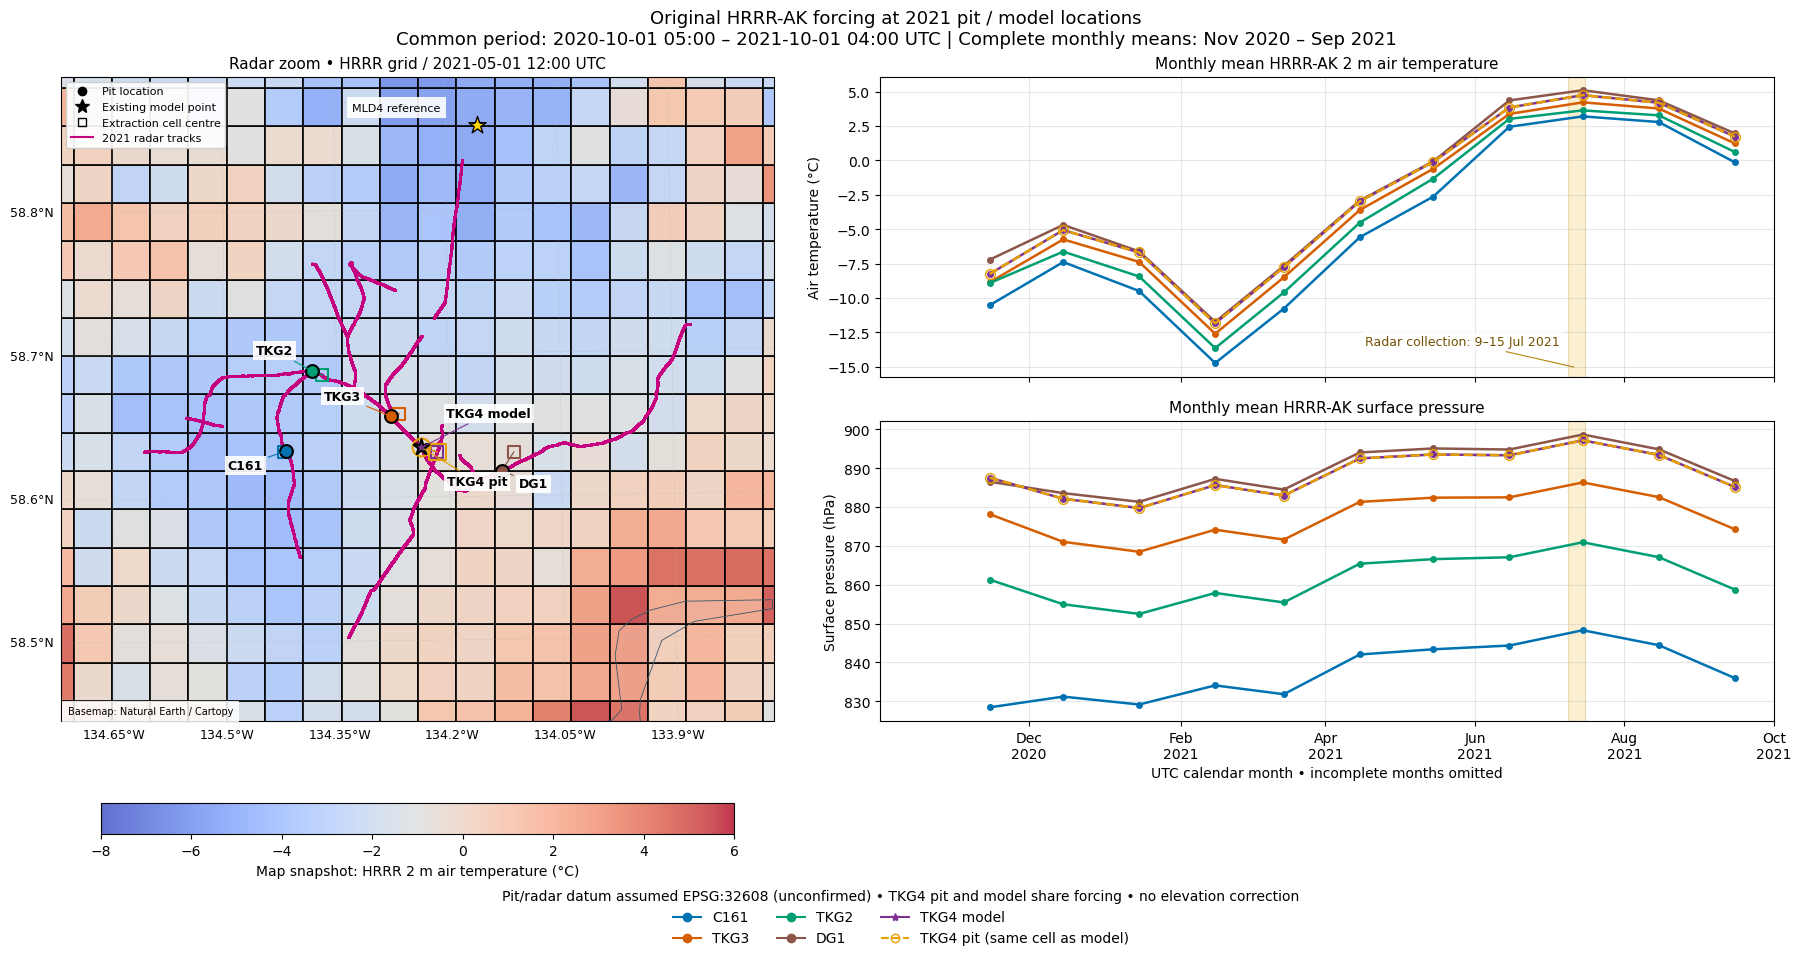

In [5]:
map_crs = ccrs.epsg(grid_crs.to_epsg())
fig = plt.figure(figsize=(18, 9.5), layout='constrained')
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.2])
ax_map = fig.add_subplot(gs[:, 0], projection=map_crs)
ax_temp = fig.add_subplot(gs[0, 1])
ax_pressure = fig.add_subplot(gs[1, 1], sharex=ax_temp)
map_temp = snapshot.temp.values - 273.15
finite = map_temp[np.isfinite(map_temp)]
vmin, vmax = np.floor(finite.min()), np.ceil(finite.max())
if vmin == vmax:
    vmax += 1
ax_map.add_feature(cfeature.OCEAN.with_scale('10m'), facecolor='#dcecf4', zorder=0)
ax_map.add_feature(cfeature.LAND.with_scale('10m'), facecolor='#eef0e7', zorder=0)
ax_map.pcolormesh(x_edges, y_edges, np.where(np.isfinite(map_temp), np.nan, 1),
                  transform=map_crs, cmap='Greys', vmin=0, vmax=2, zorder=1)
mesh = ax_map.pcolormesh(x_edges, y_edges, np.ma.masked_invalid(map_temp), transform=map_crs,
    cmap='coolwarm', vmin=vmin, vmax=vmax, shading='flat', alpha=0.8,
    edgecolors=(0, 0, 0, 0.22), linewidth=0.2, zorder=2)
ax_map.coastlines(resolution='10m', color='#38566b', linewidth=0.6, zorder=3)
for bounds, color in [(hrrr_bounds, 'royalblue'), (dem_bounds, 'darkorange')]:
    left, bottom, right, top = bounds
    ax_map.add_patch(Rectangle((left, bottom), right-left, top-bottom, transform=map_crs,
                              fill=False, edgecolor=color, linewidth=1.8, zorder=4))
ax_map.scatter(radar_x, radar_y, transform=map_crs, s=0.6, color='#c6007e', rasterized=True, zorder=5)
offsets = {'C161': (-42, -13), 'TKG3': (-48, 12), 'TKG2': (-40, 12),
           'DG1': (12, -12), 'TKG4 model': (18, 22), 'TKG4 pit': (18, -27)}
# Shared-cell outlines use nested square sizes to show both site colors at one centre.
for site in sites.itertuples():
    color = SITE_COLORS[site.label]
    size = 140 if site.label == 'TKG4 pit' else 75
    ax_map.scatter(site.cell_x, site.cell_y, s=size, marker='s', facecolors='none',
                   edgecolors=color, linewidth=1.5, transform=map_crs, zorder=7)
    ax_map.plot([site.grid_x, site.cell_x], [site.grid_y, site.cell_y], color=color,
                linewidth=0.9, transform=map_crs, zorder=6)
    ax_map.scatter(site.grid_x, site.grid_y, s=140 if site.kind == 'model' else (165 if site.label == 'TKG4 pit' else 85),
        marker='*' if site.kind == 'model' else 'o',
        facecolors='none' if site.label == 'TKG4 pit' else color,
        edgecolors=color if site.label == 'TKG4 pit' else 'black', linewidth=1.5,
        transform=map_crs, zorder=10 if site.kind == 'model' else 9)
    ax_map.annotate(site.label, (site.grid_x, site.grid_y), xytext=offsets[site.label],
        textcoords='offset points', fontsize=9, fontweight='bold', zorder=12,
        bbox={'facecolor': 'white', 'alpha': 0.92, 'edgecolor': 'none', 'pad': 2},
        arrowprops={'arrowstyle': '-', 'color': color, 'lw': 0.8})
ml_x, ml_y = Transformer.from_crs(4326, grid_crs, always_xy=True).transform(-134.15728, 58.85892)
ax_map.scatter(ml_x, ml_y, s=170, marker='*', facecolor='#ffd700', edgecolor='black', transform=map_crs, zorder=9)
ax_map.annotate('MLD4 reference', (ml_x, ml_y), xytext=(-90, 10), textcoords='offset points',
                fontsize=8, bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})
ax_map.set_xlim(zoom_bounds[0], zoom_bounds[2]); ax_map.set_ylim(zoom_bounds[1], zoom_bounds[3])
grid = ax_map.gridlines(draw_labels=True, linewidth=0.3, alpha=0.4)
grid.top_labels = False; grid.right_labels = False
grid.xlabel_style = {'size': 9}; grid.ylabel_style = {'size': 9}
ax_map.set_title(f'Radar zoom • HRRR grid / {pd.Timestamp(snapshot.time.values):%Y-%m-%d %H:%M} UTC', fontsize=11)
map_handles = [Line2D([], [], marker='o', color='black', linestyle='none', label='Pit location'),
               Line2D([], [], marker='*', color='black', linestyle='none', markersize=10, label='Existing model point'),
               Line2D([], [], marker='s', markerfacecolor='none', color='black', linestyle='none', label='Extraction cell centre'),
               Line2D([], [], color='#c6007e', label='2021 radar tracks')]
ax_map.legend(handles=map_handles, loc='upper left', fontsize=8, framealpha=0.92)
ax_map.text(0.01, 0.01, 'Basemap: Natural Earth / Cartopy', transform=ax_map.transAxes, fontsize=7,
            bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none'})
fig.colorbar(mesh, ax=ax_map, orientation='horizontal', shrink=0.85, pad=0.03,
             label='Map snapshot: HRRR 2 m air temperature (°C)')

midmonth = monthly_temp.index + pd.Timedelta(days=14)
for site in sites.itertuples():
    is_pit_context = site.label == 'TKG4 pit'
    style = {'color': SITE_COLORS[site.label], 'linestyle': '--' if is_pit_context else '-',
             'marker': 'o', 'markersize': 7 if is_pit_context else 4,
             'markerfacecolor': 'none' if is_pit_context else SITE_COLORS[site.label],
             'linewidth': 1.8, 'label': site.label}
    ax_temp.plot(midmonth, monthly_temp[site.label], **style)
    ax_pressure.plot(midmonth, monthly_pressure[site.label], **style)
for ax in [ax_temp, ax_pressure]:
    ax.axvspan(RADAR_COLLECTION_START, RADAR_COLLECTION_END_EXCLUSIVE,
               facecolor='#f2c14e', alpha=0.25, edgecolor='#b8860b', linewidth=0.8,
               zorder=0.5)
    ax.grid(alpha=0.3)
    ax.set_xlim(common_start, common_end)
ax_temp.annotate('Radar collection: 9–15 Jul 2021',
    xy=(RADAR_COLLECTION_START + (RADAR_COLLECTION_END_EXCLUSIVE - RADAR_COLLECTION_START) / 2, 0.03),
    xycoords=('data', 'axes fraction'), xytext=(-12, 14), textcoords='offset points',
    ha='right', va='bottom', fontsize=9, color='#725200',
    bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'none', 'pad': 2},
    arrowprops={'arrowstyle': '-', 'color': '#b8860b', 'lw': 0.8})
ax_temp.set_title('Monthly mean HRRR-AK 2 m air temperature', fontsize=11)
ax_temp.set_ylabel('Air temperature (°C)')
ax_pressure.set_title('Monthly mean HRRR-AK surface pressure', fontsize=11)
ax_pressure.set_ylabel('Surface pressure (hPa)')
ax_pressure.set_xlabel('UTC calendar month • incomplete months omitted')
ax_pressure.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_pressure.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
plt.setp(ax_temp.get_xticklabels(), visible=False)
fig.suptitle('Original HRRR-AK forcing at 2021 pit / model locations\n'
    f'Common period: {common_start:%Y-%m-%d %H:%M} – {common_end:%Y-%m-%d %H:%M} UTC | '
    f'Complete monthly means: {valid_months.min():%b %Y} – {valid_months.max():%b %Y}', fontsize=13)
site_handles = [Line2D([], [], color=SITE_COLORS[s], marker='*' if s == 'TKG4 model' else 'o',
    linestyle='--' if s == 'TKG4 pit' else '-', markerfacecolor='none' if s == 'TKG4 pit' else SITE_COLORS[s],
    label=s + (' (same cell as model)' if s == 'TKG4 pit' else '')) for s in SITE_ORDER]
fig.legend(handles=site_handles, loc='outside lower center', ncol=3, fontsize=10, frameon=False,
    title='Pit/radar datum assumed EPSG:32608 (unconfirmed) • TKG4 pit and model share forcing • no elevation correction')
if SAVE_OUTPUTS:
    figure_path = FIGURE_DIR / 'radar_pit_hrrrak_forcing_comparison_2021_sites.png'
    fig.savefig(figure_path, dpi=180, bbox_inches='tight')
    print('Saved:', figure_path)
plt.show()
plt.close(fig)
assert hashlib.sha256(REFERENCE_PATH.read_bytes()).hexdigest() == reference_sha256, 'Reference notebook changed.'

## Interpretation and limitations

- Shared cells reuse exactly the same original forcing; overlapping curves do not imply equal site elevations or independent forcing information.
- Pit date flags and TKG4's pit/model elevation discrepancy require review before choosing validation sites. The summary keeps pit and model elevations separate.
- The provisional horizontal datum and unverified vertical datum prevent treating coordinate/elevation differences as precise terrain corrections.
- Surface pressure is taken directly from the stored surface-pressure field. Orography varies in this file; its range is retained for review rather than applying corrections.
- Partial or missing calendar months are omitted using the strict hourly-completeness rule. The monthly export preserves the coverage counts and NaN means.
- The reference notebook and source datasets are read-only inputs. Figures and summary CSVs follow the project's existing output directories.